In [1]:
import sys, json, warnings, inspect, hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,
                             max_error, accuracy_score, precision_recall_fscore_support, confusion_matrix)

try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# ---- Project root: Google Colab (Drive is mounted here) or local VS Code / Jupyter ----
IN_COLAB = False
try:
    from google.colab import drive          # only exists inside Google Colab
    IN_COLAB = True
except ImportError:
    pass

if IN_COLAB:
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/heatwave-delhi")      # folder must sit directly in My Drive
    ROOT.mkdir(parents=True, exist_ok=True)
else:
    _cwd = Path.cwd().resolve()
    if _cwd.name == "heatwave-delhi":
        ROOT = _cwd
    elif (_cwd / "heatwave-delhi").is_dir():
        ROOT = _cwd / "heatwave-delhi"
    elif _cwd.name == "notebooks":
        ROOT = _cwd.parent
    else:
        ROOT = _cwd
print("Project root:", ROOT)

DIRS = {
    "processed": ROOT / "data" / "processed",
    "config":    ROOT / "config",
    "features":  ROOT / "reports" / "features",
    "reports":   ROOT / "reports",
    "src":       ROOT / "src",
    "models":    ROOT / "models",      # only the saved imputer (no ML model is trained here)
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi
Project root: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi


In [2]:
# ----------------------- ALL project settings live here -----------------------
CLEAN_CSV = DIRS["processed"] / "delhi_daily_clean.csv"

VARS = ["tmax", "humidity", "wind", "solar"]
UNITS = {"tmax": "°C", "humidity": "%", "wind": "km/h", "solar": "MJ/m²"}

START, END = pd.Timestamp("2015-01-01"), pd.Timestamp("2025-12-31")
FULL_INDEX = pd.date_range(START, END, freq="D", name="date")
EXPECTED_DAYS = len(FULL_INDEX)
assert EXPECTED_DAYS == 4018, EXPECTED_DAYS

# Forecasting set-up (pooled direct multi-horizon)
HORIZONS = [1, 2, 3]                 # forecast_horizon values: T+1, T+2, T+3
LAGS = [0, 1, 2]                     # d0 = T, d1 = T-1, d2 = T-2  (3 completed days)
TARGET = "target_tmax"
META_COLS = ["forecast_origin", "target_date"]     # tracking only - NOT model inputs

# The 21 candidate input features (12 + 4 + 4 + 1)
HIST_FEATURES = [f"{v}_d{k}" for v in VARS for k in LAGS]
SEASONAL_FEATURES = ["month_sin", "month_cos", "day_sin", "day_cos"]
TREND_FEATURES = ["tmax_mean_3d", "tmax_trend_3d", "humidity_mean_3d", "solar_sum_3d"]
HORIZON_FEATURE = ["forecast_horizon"]
FEATURE_COLUMNS = HIST_FEATURES + SEASONAL_FEATURES + TREND_FEATURES + HORIZON_FEATURE
assert len(FEATURE_COLUMNS) == 21

# Chronological split - membership decided by TARGET date (never random)
SPLIT_BOUNDS = {
    "train":      ("2015-01-01", "2022-12-31"),
    "validation": ("2023-01-01", "2024-12-31"),
    "test":       ("2025-01-01", "2025-12-31"),
}
SPLIT_COLORS = {"train": "#4c78a8", "validation": "#f58518", "test": "#54a24b"}

# Simplified absolute-temperature heatwave rule (used AFTER regression, never as a target)
HEATWAVE_C, SEVERE_C = 45.0, 47.0
CATEGORY_NAMES = {0: "No Heatwave", 1: "Heatwave", 2: "Severe Heatwave"}
CLASS_LABELS = [0, 1, 2]

SEED = 42                            # only for random SPOT-CHECKS, never for splitting
print("Features:", len(FEATURE_COLUMNS), "| horizons:", HORIZONS, "| target:", TARGET)

Features: 21 | horizons: [1, 2, 3] | target: target_tmax


LOAD CLEANED DATASET

In [3]:
# Find the clean CSV (Drive/project folder first; in Colab fall back to /content or an upload box)
candidates = [CLEAN_CSV, ROOT / "delhi_daily_clean.csv", Path("/content/delhi_daily_clean.csv"), Path.cwd() / "delhi_daily_clean.csv"]
found = next((p for p in candidates if p.exists()), None)
if found is None and "google.colab" in sys.modules:
    from google.colab import files
    print("delhi_daily_clean.csv not found -> please upload it")
    up = files.upload()
    CLEAN_CSV.write_bytes(up[next(iter(up))])
    found = CLEAN_CSV
if found is None:
    raise FileNotFoundError("delhi_daily_clean.csv not found - put it in data/processed/")
if found.resolve() != CLEAN_CSV.resolve():
    CLEAN_CSV.write_bytes(found.read_bytes())       # work from data/processed/, source file stays untouched

clean = pd.read_csv(CLEAN_CSV, parse_dates=["date"])
csv_md5 = hashlib.md5(CLEAN_CSV.read_bytes()).hexdigest()

print("Loaded:", CLEAN_CSV)
print("First 5 rows"); display(clean.head())
print("Last 5 rows");  display(clean.tail())
print(f"Rows: {clean.shape[0]} | Columns: {clean.shape[1]} | {clean['date'].min().date()} -> {clean['date'].max().date()}")
clean.info()

Loaded: C:\Users\Shreya Mehrotra\Desktop\heatwave-delhi\data\processed\delhi_daily_clean.csv
First 5 rows


,date,tmax,humidity,wind,solar
0,2015-01-01,21.0,73.0,8.9,10.17
1,2015-01-02,15.9,88.0,11.2,4.91
2,2015-01-03,16.6,91.0,9.0,4.59
3,2015-01-04,18.1,85.0,13.5,12.68
4,2015-01-05,20.4,78.0,27.0,14.72


Last 5 rows


,date,tmax,humidity,wind,solar
4013,2025-12-27,20.0,83.0,11.2,13.05
4014,2025-12-28,19.4,86.0,9.4,14.16
4015,2025-12-29,18.2,90.0,8.2,12.71
4016,2025-12-30,18.5,87.0,9.2,12.99
4017,2025-12-31,17.8,93.0,13.5,12.51


Rows: 4018 | Columns: 5 | 2015-01-01 -> 2025-12-31
<class 'pandas.DataFrame'>
RangeIndex: 4018 entries, 0 to 4017
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      4018 non-null   datetime64[us]
 1   tmax      4018 non-null   float64       
 2   humidity  4018 non-null   float64       
 3   wind      4018 non-null   float64       
 4   solar     4018 non-null   float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 157.1 KB


CONFIRM DATASET QUALITY

In [4]:
dates = clean["date"]
checks = {
    "columns are exactly date + 4 vars": list(clean.columns) == ["date"] + VARS,
    "4,018 rows": len(clean) == EXPECTED_DAYS,
    "dates unique & strictly increasing": dates.is_unique and dates.is_monotonic_increasing,
    "dates match the full 2015-2025 calendar": (dates.values == FULL_INDEX.values).all(),
    "leap days present (2016, 2020, 2024)": all(pd.Timestamp(f"{y}-02-29") in set(dates) for y in (2016, 2020, 2024)),
    "weather columns numeric": all(pd.api.types.is_numeric_dtype(clean[c]) for c in VARS),
    "no missing values": int(clean[VARS].isna().sum().sum()) == 0,
    "no infinite values": not np.isinf(clean[VARS]).any().any(),
    "humidity within [0, 100]": clean["humidity"].between(0, 100).all(),
    "wind >= 0": (clean["wind"] >= 0).all(),
    "solar >= 0": (clean["solar"] >= 0).all(),
}
quality = pd.Series(checks, name="passed").to_frame()
display(quality)
assert quality["passed"].all(), "Dataset quality check failed - fix the clean data first."

print("Missing values per column:"); print(clean[VARS].isna().sum().to_string())
clean[VARS].describe().T.round(3)

,passed
columns are exactly date + 4 vars,True
"4,018 rows",True
dates unique & strictly increasing,True
dates match the full 2015-2025 calendar,True
"leap days present (2016, 2020, 2024)",True
weather columns numeric,True
no missing values,True
no infinite values,True
"humidity within [0, 100]",True
wind >= 0,True


Missing values per column:
tmax        0
humidity    0
wind        0
solar       0


,count,mean,std,min,25%,50%,75%,max
tmax,4018.0,31.100,6.809,10.3,26.20,32.40,35.600,46.50
humidity,4018.0,66.961,16.027,21.0,58.00,70.00,79.000,99.00
wind,4018.0,13.767,4.548,5.5,10.20,13.00,16.400,32.30
solar,4018.0,18.599,5.145,1.2,14.84,18.37,22.625,29.21


FORECAST ORIGINS

In [5]:
# T = most recent COMPLETED day. Inputs: T-2, T-1, T. Targets: T+1, T+2, T+3.
# A complete daily calendar makes a missing day show up as NaN, so a shift can never grab the wrong day.
def make_calendar(df):
    out = df.copy()
    out["date"] = pd.to_datetime(out["date"])
    out = out.sort_values("date").set_index("date")
    full = pd.date_range(out.index.min(), out.index.max(), freq="D")
    return out[VARS].reindex(full).rename_axis("date")

daily = make_calendar(clean)
print("Calendar days:", len(daily), "| rows with any NaN after reindex:", int(daily.isna().any(axis=1).sum()))
print("First valid origin :", daily.index[2].date(), "(needs T-2 and T-1)")
print("Last  valid origin :", daily.index[-2].date(), "(only the horizon-1 target exists)")

ex = pd.Timestamp("2023-05-12")
print(f"\nExample origin {ex.date()}:")
print("  input days :", [(ex - pd.Timedelta(days=k)).date().isoformat() for k in (2, 1, 0)])
print("  target days:", [(ex + pd.Timedelta(days=h)).date().isoformat() for h in HORIZONS])

Calendar days: 4018 | rows with any NaN after reindex: 0
First valid origin : 2015-01-03 (needs T-2 and T-1)
Last  valid origin : 2025-12-30 (only the horizon-1 target exists)

Example origin 2023-05-12:
  input days : ['2023-05-10', '2023-05-11', '2023-05-12']
  target days: ['2023-05-13', '2023-05-14', '2023-05-15']


HISTORICAL WEATHER FEATURES (12)

In [6]:
def add_historical_features(daily):
    # shift(k) moves data FORWARD in time: row T receives the value observed on T-k (past only).
    feats = pd.DataFrame(index=daily.index)
    for var in VARS:
        for k in LAGS:
            feats[f"{var}_d{k}"] = daily[var].shift(k)
    feats.index.name = "forecast_origin"
    return feats

hist = add_historical_features(daily)
print(len(hist.columns), "historical features:", list(hist.columns))
display(hist.iloc[2:7])

# alignment proof
t = pd.Timestamp("2020-06-15")
for k in LAGS:
    print(f"tmax_d{k} = {hist.loc[t, f'tmax_d{k}']}  ==  raw tmax on {(t - pd.Timedelta(days=k)).date()} = {daily.loc[t - pd.Timedelta(days=k), 'tmax']}")

12 historical features: ['tmax_d0', 'tmax_d1', 'tmax_d2', 'humidity_d0', 'humidity_d1', 'humidity_d2', 'wind_d0', 'wind_d1', 'wind_d2', 'solar_d0', 'solar_d1', 'solar_d2']


,tmax_d0,tmax_d1,tmax_d2,humidity_d0,humidity_d1,humidity_d2,wind_d0,wind_d1,wind_d2,solar_d0,solar_d1,solar_d2
forecast_origin,,,,,,,,,,,,
2015-01-03,16.6,15.9,21.0,91.0,88.0,73.0,9.0,11.2,8.9,4.59,4.91,10.17
2015-01-04,18.1,16.6,15.9,85.0,91.0,88.0,13.5,9.0,11.2,12.68,4.59,4.91
2015-01-05,20.4,18.1,16.6,78.0,85.0,91.0,27.0,13.5,9.0,14.72,12.68,4.59
2015-01-06,18.1,20.4,18.1,80.0,78.0,85.0,21.7,27.0,13.5,12.46,14.72,12.68
2015-01-07,16.7,18.1,20.4,83.0,80.0,78.0,11.3,21.7,27.0,8.16,12.46,14.72


tmax_d0 = 40.8  ==  raw tmax on 2020-06-15 = 40.8
tmax_d1 = 37.6  ==  raw tmax on 2020-06-14 = 37.6
tmax_d2 = 37.7  ==  raw tmax on 2020-06-13 = 37.7


SEASONAL FEATURES (4)

C:\Users\Shreya Mehrotra\AppData\Local\Temp\ipykernel_22784\620381294.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(demo.round(4))


,target_date,month_sin,month_cos,day_sin,day_cos
0,2023-01-01,0.0,1.000,0.0000,1.0000
1,2023-06-15,0.5,-0.866,0.2967,-0.9550
2,2023-12-31,-0.5,0.866,-0.0172,0.9999
3,2024-01-01,0.0,1.000,0.0000,1.0000
4,2024-12-31,-0.5,0.866,-0.0172,0.9999


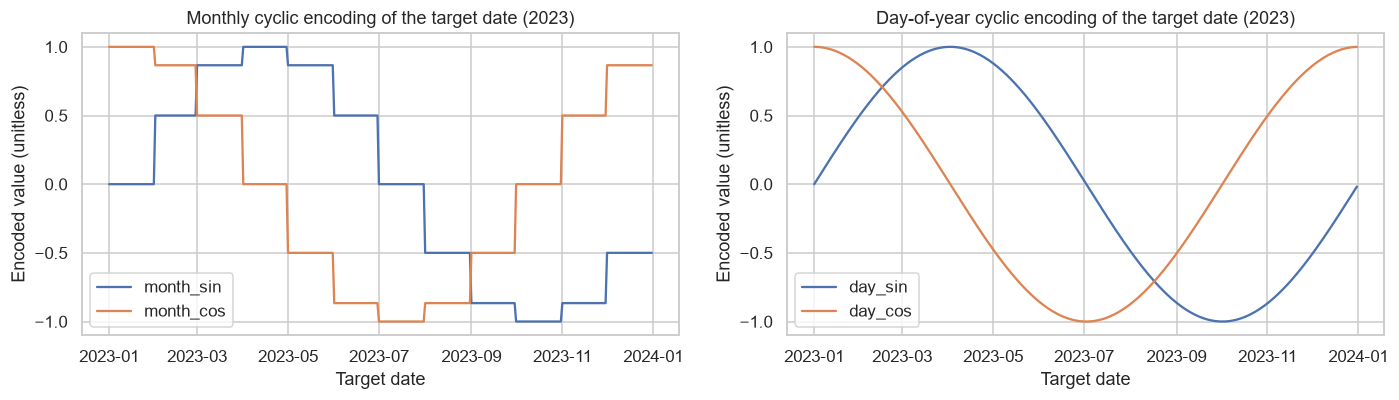

In [7]:
def add_seasonal_features(target_dates):
    # Cyclic encoding of the TARGET date (the day being predicted).
    #   month_sin/cos = sin/cos(2*pi*(month-1)/12)
    #   day_sin/cos   = sin/cos(2*pi*(day_of_year-1)/days_in_year), days_in_year = 365 or 366 (leap-aware),
    #                   so 1 Jan is always angle 0 and the year always closes the circle.
    td = pd.DatetimeIndex(target_dates)
    month_angle = 2 * np.pi * (td.month.values - 1) / 12
    day_angle = 2 * np.pi * (td.dayofyear.values - 1) / np.where(td.is_leap_year, 366, 365)
    return pd.DataFrame({"month_sin": np.sin(month_angle), "month_cos": np.cos(month_angle),
                         "day_sin": np.sin(day_angle), "day_cos": np.cos(day_angle)})

demo_dates = pd.to_datetime(["2023-01-01", "2023-06-15", "2023-12-31", "2024-01-01", "2024-12-31"])
demo = add_seasonal_features(demo_dates)
demo.insert(0, "target_date", demo_dates)
display(demo.round(4))

d = pd.date_range("2023-01-01", "2023-12-31")
s = add_seasonal_features(d)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for col in ("month_sin", "month_cos"):
    ax[0].plot(d, s[col], label=col)
for col in ("day_sin", "day_cos"):
    ax[1].plot(d, s[col], label=col)
ax[0].set_title("Monthly cyclic encoding of the target date (2023)")
ax[1].set_title("Day-of-year cyclic encoding of the target date (2023)")
for a in ax:
    a.set_xlabel("Target date"); a.set_ylabel("Encoded value (unitless)"); a.legend()
plt.tight_layout(); plt.savefig(DIRS["features"] / "seasonal_encoding.png"); plt.show()

ROLLING / TREND FEATURES (4)

In [8]:
def add_trend_features(feats):
    # Only the 3-day INPUT window is used -> strictly backward-looking.
    out = feats.copy()
    out["tmax_mean_3d"] = out[["tmax_d0", "tmax_d1", "tmax_d2"]].mean(axis=1, skipna=False)
    out["tmax_trend_3d"] = out["tmax_d0"] - out["tmax_d2"]
    out["humidity_mean_3d"] = out[["humidity_d0", "humidity_d1", "humidity_d2"]].mean(axis=1, skipna=False)
    out["solar_sum_3d"] = out[["solar_d0", "solar_d1", "solar_d2"]].sum(axis=1, skipna=False)
    return out

display(add_trend_features(hist)[TREND_FEATURES].iloc[2:8].round(2))

,tmax_mean_3d,tmax_trend_3d,humidity_mean_3d,solar_sum_3d
forecast_origin,,,,
2015-01-03,17.83,-4.4,84.00,19.67
2015-01-04,16.87,2.2,88.00,22.18
2015-01-05,18.37,3.8,84.67,31.99
2015-01-06,18.87,0.0,81.00,39.86
2015-01-07,18.40,-3.7,80.33,35.34
2015-01-08,17.43,-0.6,83.33,34.82


FORECAST HORIZON + TARGET (SUPERVISED DATASET)

In [9]:
def build_supervised(daily):
    # One origin -> up to 3 rows (horizon 1, 2, 3): same weather inputs, different horizon / target date / target.
    hist = add_trend_features(add_historical_features(daily)).iloc[max(LAGS):]   # first 2 days have no 3-day window
    parts = []
    for h in HORIZONS:
        part = hist.copy()
        part["forecast_origin"] = part.index
        part["target_date"] = part["forecast_origin"] + pd.Timedelta(days=h)
        part["forecast_horizon"] = h
        part[TARGET] = daily["tmax"].reindex(part["target_date"]).values       # actual Tmax on T+h (NaN if absent)
        seas = add_seasonal_features(part["target_date"]); seas.index = part.index
        parts.append(pd.concat([part, seas], axis=1).reset_index(drop=True))
    sup = pd.concat(parts, ignore_index=True)
    sup["has_missing_predictor"] = sup[FEATURE_COLUMNS].isna().any(axis=1).astype(int)
    sup = sup[sup[TARGET].notna()].copy()                                      # never fabricate targets
    sup = sup.sort_values(["target_date", "forecast_horizon"]).reset_index(drop=True)
    return sup[META_COLS + FEATURE_COLUMNS + [TARGET, "has_missing_predictor"]]

sup = build_supervised(daily)
print("Supervised dataset:", sup.shape, "| inputs:", len(FEATURE_COLUMNS), "| target:", TARGET)
print("Rows per horizon:", sup["forecast_horizon"].value_counts().sort_index().to_dict())
print("\nOne origin -> three rows (2023-05-12):")
display(sup[sup["forecast_origin"] == pd.Timestamp("2023-05-12")][
    ["forecast_origin", "forecast_horizon", "target_date", "tmax_d0", "tmax_d1", "tmax_d2", "month_sin", "day_sin", TARGET]].round(3))

Supervised dataset: (12042, 25) | inputs: 21 | target: target_tmax
Rows per horizon: {1: 4015, 2: 4014, 3: 4013}

One origin -> three rows (2023-05-12):


C:\Users\Shreya Mehrotra\AppData\Local\Temp\ipykernel_22784\1177294665.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ["forecast_origin", "forecast_horizon", "target_date", "tmax_d0", "tmax_d1", "tmax_d2", "month_sin", "day_sin", TARGET]].round(3))


,forecast_origin,forecast_horizon,target_date,tmax_d0,tmax_d1,tmax_d2,month_sin,day_sin,target_tmax
9150,2023-05-12,1,2023-05-13,41.2,38.8,36.5,0.866,0.764,41.2
9154,2023-05-12,2,2023-05-14,41.2,38.8,36.5,0.866,0.753,40.8
9158,2023-05-12,3,2023-05-15,41.2,38.8,36.5,0.866,0.741,40.7


FEATURE-TARGET ALIGNMENT CHECK

In [10]:
# Independent re-computation (plain dict lookup by date, no shift) of random rows
lookup = {c: dict(zip(clean["date"], clean[c])) for c in VARS}
rng = np.random.default_rng(SEED)
idx = rng.choice(len(sup), size=600, replace=False)

bad = 0
for i in idx:
    r = sup.iloc[i]
    T, h = r["forecast_origin"], int(r["forecast_horizon"])
    td = T + pd.Timedelta(days=h)
    ok = (r["target_date"] == td) and np.isclose(r[TARGET], lookup["tmax"][td])
    for var in VARS:
        for k in LAGS:
            ok &= np.isclose(r[f"{var}_d{k}"], lookup[var][T - pd.Timedelta(days=k)])
    t3 = [lookup["tmax"][T - pd.Timedelta(days=k)] for k in LAGS]
    ok &= np.isclose(r["tmax_mean_3d"], np.mean(t3)) and np.isclose(r["tmax_trend_3d"], t3[0] - t3[2])
    ok &= np.isclose(r["humidity_mean_3d"], np.mean([lookup["humidity"][T - pd.Timedelta(days=k)] for k in LAGS]))
    ok &= np.isclose(r["solar_sum_3d"], np.sum([lookup["solar"][T - pd.Timedelta(days=k)] for k in LAGS]))
    diy = 366 if td.is_leap_year else 365                                   # calendar features = TARGET date only
    ok &= np.isclose(r["month_sin"], np.sin(2 * np.pi * (td.month - 1) / 12))
    ok &= np.isclose(r["day_cos"], np.cos(2 * np.pi * (td.dayofyear - 1) / diy))
    bad += int(not ok)

assert (sup["target_date"] == sup["forecast_origin"] + pd.to_timedelta(sup["forecast_horizon"], unit="D")).all()
print(f"Re-checked {len(idx)} random rows against the raw dates -> mismatches: {bad}")
assert bad == 0

Re-checked 600 random rows against the raw dates -> mismatches: 0


CHRONOLOGICAL SPLIT (TRAIN / VALIDATION / TEST)

In [11]:
def split_by_target_date(df, bounds):
    return {name: df[(df["target_date"] >= pd.Timestamp(a)) & (df["target_date"] <= pd.Timestamp(b))].reset_index(drop=True)
            for name, (a, b) in bounds.items()}

parts = split_by_target_date(sup, SPLIT_BOUNDS)
train_df, val_df, test_df = parts["train"], parts["validation"], parts["test"]
assert len(train_df) + len(val_df) + len(test_df) == len(sup)

rows = []
for name, p in parts.items():
    row = {"split": name, "target period": f"{SPLIT_BOUNDS[name][0]} -> {SPLIT_BOUNDS[name][1]}",
           "first target": p["target_date"].min().date(), "last target": p["target_date"].max().date(),
           "first origin": p["forecast_origin"].min().date(), "last origin": p["forecast_origin"].max().date(),
           "rows": len(p), "share_%": round(100 * len(p) / len(sup), 2)}
    for h in HORIZONS:
        row[f"h={h}"] = int((p["forecast_horizon"] == h).sum())
    rows.append(row)
split_summary = pd.DataFrame(rows).set_index("split")
split_summary

,target period,first target,last target,first origin,last origin,rows,share_%,h=1,h=2,h=3
split,,,,,,,,,,
train,2015-01-01 -> 2022-12-31,2015-01-04,2022-12-31,2015-01-03,2022-12-30,8754,72.70,2919,2918,2917
validation,2023-01-01 -> 2024-12-31,2023-01-01,2024-12-31,2022-12-29,2024-12-30,2193,18.21,731,731,731
test,2025-01-01 -> 2025-12-31,2025-01-01,2025-12-31,2024-12-29,2025-12-30,1095,9.09,365,365,365


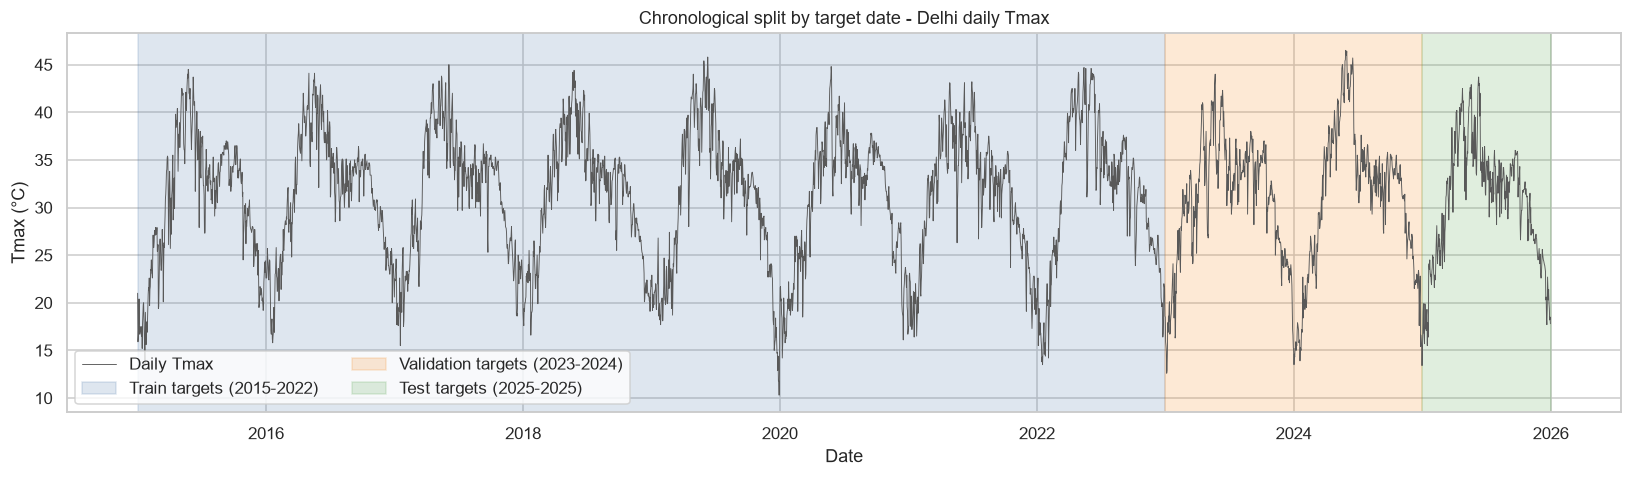

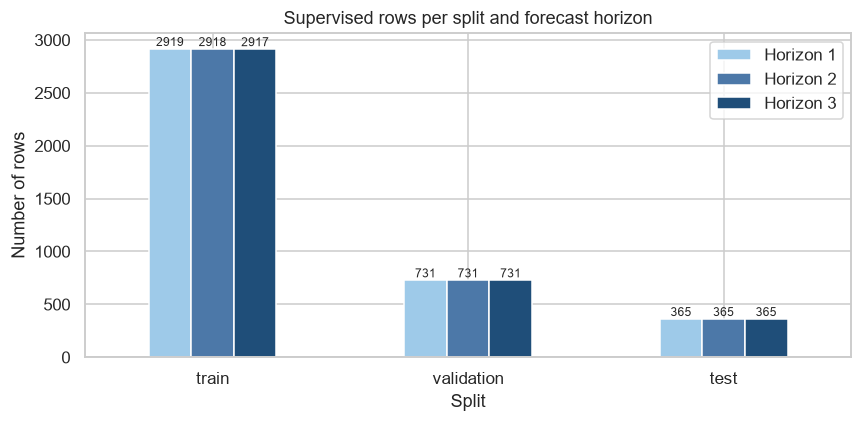

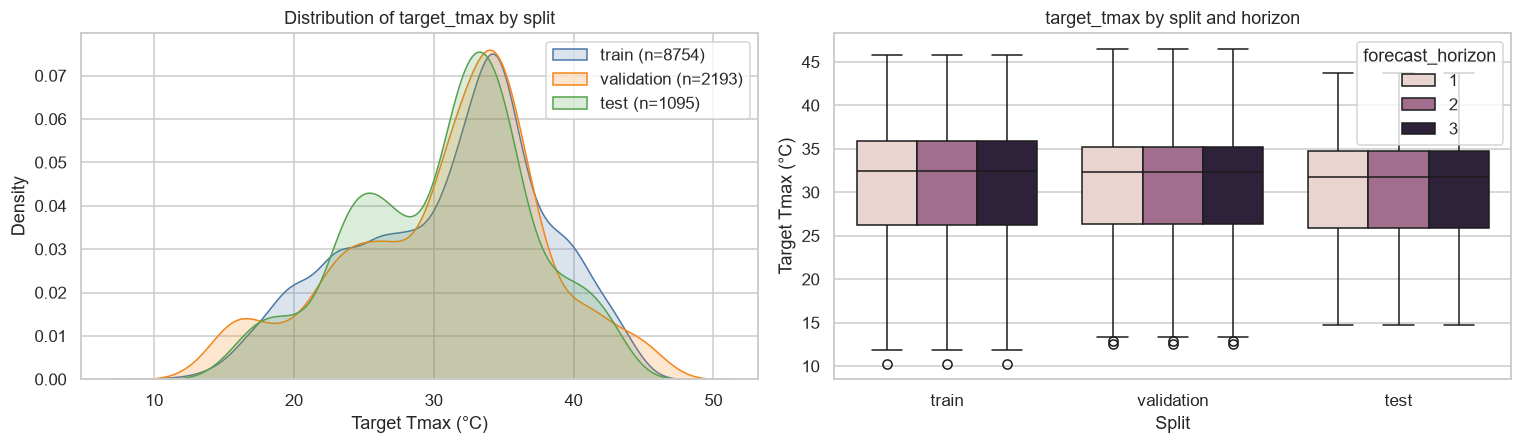

count   mean   std   min  median   max
split      forecast_horizon                                        
train      1                  2919  31.20  6.81  10.3    32.5  45.8
           2                  2918  31.21  6.80  10.3    32.5  45.8
           3                  2917  31.21  6.80  10.3    32.5  45.8
validation 1                   731  30.94  7.01  12.6    32.3  46.5
           2                   731  30.94  7.01  12.6    32.3  46.5
           3                   731  30.94  7.01  12.6    32.3  46.5
test       1                   365  30.71  6.31  14.7    31.8  43.7
           2                   365  30.71  6.31  14.7    31.8  43.7
           3                   365  30.71  6.31  14.7    31.8  43.7

In [12]:
# ---- Visual 1: split timeline over the real Tmax series ----
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(daily.index, daily["tmax"], color="0.35", lw=0.6, label="Daily Tmax")
for name, (a, b) in SPLIT_BOUNDS.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=SPLIT_COLORS[name], alpha=0.18,
               label=f"{name.capitalize()} targets ({a[:4]}-{b[:4]})")
ax.set_title("Chronological split by target date - Delhi daily Tmax")
ax.set_xlabel("Date"); ax.set_ylabel("Tmax (°C)"); ax.legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.savefig(DIRS["features"] / "split_timeline.png"); plt.show()

# ---- Visual 2: rows per split and horizon ----
cnt = pd.DataFrame({n: p["forecast_horizon"].value_counts().sort_index() for n, p in parts.items()})
cnt.index = [f"Horizon {h}" for h in cnt.index]
ax = cnt.T.plot(kind="bar", figsize=(8, 4), color=["#9ecae9", "#4c78a8", "#1f4e79"], rot=0)
ax.set_title("Supervised rows per split and forecast horizon"); ax.set_xlabel("Split"); ax.set_ylabel("Number of rows")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.tight_layout(); plt.savefig(DIRS["features"] / "split_counts.png"); plt.show()

# ---- Visual 3: target distribution by split / horizon ----
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name, p in parts.items():
    sns.kdeplot(p[TARGET], ax=ax[0], label=f"{name} (n={len(p)})", color=SPLIT_COLORS[name], fill=True, alpha=0.2)
ax[0].set_title("Distribution of target_tmax by split"); ax[0].set_xlabel("Target Tmax (°C)"); ax[0].set_ylabel("Density"); ax[0].legend()
allp = pd.concat([p.assign(split=n) for n, p in parts.items()])
sns.boxplot(data=allp, x="split", y=TARGET, hue="forecast_horizon", order=list(parts), ax=ax[1])
ax[1].set_title("target_tmax by split and horizon"); ax[1].set_xlabel("Split"); ax[1].set_ylabel("Target Tmax (°C)")
plt.tight_layout(); plt.savefig(DIRS["features"] / "target_distribution_by_split.png"); plt.show()

target_stats = allp.groupby(["split", "forecast_horizon"])[TARGET].agg(["count", "mean", "std", "min", "median", "max"]).round(2)
target_stats.reindex(list(parts), level=0)

LEAKAGE-SAFE PREPROCESSING

In [13]:
# J1: missing predictors per split, then a median imputer fitted on TRAIN ONLY (no-op if nothing is missing)
miss = pd.DataFrame({n: {"rows": len(p), "rows with missing predictor": int(p["has_missing_predictor"].sum()),
                         "max column missing %": round(p[FEATURE_COLUMNS].isna().mean().max() * 100, 3)}
                     for n, p in parts.items()}).T
display(miss)

imputer = SimpleImputer(strategy="median").fit(train_df[FEATURE_COLUMNS])
assert np.allclose(imputer.statistics_, train_df[FEATURE_COLUMNS].median().values), "imputer not fitted on train only"

def apply_imputer(p):
    out = p.copy()
    out[FEATURE_COLUMNS] = imputer.transform(p[FEATURE_COLUMNS])
    return out

train_p, val_p, test_p = apply_imputer(train_df), apply_imputer(val_df), apply_imputer(test_df)

# J2: no scaling (tree-based XGBoost does not need it). J3: type checks
for name, p in {"train": train_p, "validation": val_p, "test": test_p}.items():
    X = p[FEATURE_COLUMNS]
    assert X.shape[1] == 21 and all(pd.api.types.is_numeric_dtype(X[c]) for c in FEATURE_COLUMNS)
    assert np.isfinite(X.to_numpy(float)).all() and np.isfinite(p[TARGET]).all()
    assert not X.select_dtypes(include=["datetime", "object"]).shape[1]
print("Imputer fitted on", len(train_df), "training rows only | all 21 inputs + target numeric and finite | no scaling applied")

,rows,rows with missing predictor,max column missing %
train,8754.0,0.0,0.0
validation,2193.0,0.0,0.0
test,1095.0,0.0,0.0


Imputer fitted on 8754 training rows only | all 21 inputs + target numeric and finite | no scaling applied


In [14]:
# ---- Leakage checklist ----
keys = [set(zip(p["forecast_origin"], p["forecast_horizon"])) for p in (train_df, val_df, test_df)]
leak = {
    "target / date columns are NOT among the 21 predictors": not ({TARGET, *META_COLS} & set(FEATURE_COLUMNS)),
    "every input day <= forecast origin < target date": bool((sup["forecast_origin"] < sup["target_date"]).all()),
    "trend features use only the 3-day input window": bool(
        np.allclose(sup["tmax_mean_3d"], sup[["tmax_d0", "tmax_d1", "tmax_d2"]].mean(axis=1))
        and np.allclose(sup["tmax_trend_3d"], sup["tmax_d0"] - sup["tmax_d2"])
        and np.allclose(sup["solar_sum_3d"], sup[["solar_d0", "solar_d1", "solar_d2"]].sum(axis=1))),
    "lags date-aligned (independent re-check: 0 mismatches)": bad == 0,
    "calendar features use the target date only": bad == 0,
    "no shuffling: each split sorted by target date": all(p["target_date"].is_monotonic_increasing for p in (train_df, val_df, test_df)),
    "imputer fitted on training data only": bool(np.allclose(imputer.statistics_, train_df[FEATURE_COLUMNS].median().values)),
    "no feature selection yet (all 21 candidates kept)": len(FEATURE_COLUMNS) == 21,
    "no synthetic rows (target == real Tmax of target date)": bool((sup[TARGET] == sup["target_date"].map(lookup["tmax"])).all()),
    "no duplicate (origin, horizon) inside / across splits": len(keys[0] | keys[1] | keys[2]) == sum(len(k) for k in keys) == len(sup),
    "train targets <= 2022-12-31": bool(train_df["target_date"].max() <= pd.Timestamp("2022-12-31")),
    "validation targets within 2023-2024": bool(val_df["target_date"].min() >= pd.Timestamp("2023-01-01") and val_df["target_date"].max() <= pd.Timestamp("2024-12-31")),
    "test targets within 2025": bool(test_df["target_date"].min() >= pd.Timestamp("2025-01-01")),
    "target-date ranges disjoint (train < val < test)": bool(train_df["target_date"].max() < val_df["target_date"].min() and val_df["target_date"].max() < test_df["target_date"].min()),
}
leak_df = pd.Series(leak, name="passed").to_frame()
display(leak_df)
assert leak_df["passed"].all(), "A leakage check failed!"

,passed
target / date columns are NOT among the 21 predictors,True
every input day <= forecast origin < target date,True
trend features use only the 3-day input window,True
lags date-aligned (independent re-check: 0 mismatches),True
calendar features use the target date only,True
no shuffling: each split sorted by target date,True
imputer fitted on training data only,True
no feature selection yet (all 21 candidates kept),True
no synthetic rows (target == real Tmax of target date),True
"no duplicate (origin, horizon) inside / across splits",True


X / y ARRAYS

In [15]:
X_train, y_train = train_p[FEATURE_COLUMNS].copy(), train_p[TARGET].copy()
X_val,   y_val   = val_p[FEATURE_COLUMNS].copy(),   val_p[TARGET].copy()
X_test,  y_test  = test_p[FEATURE_COLUMNS].copy(),  test_p[TARGET].copy()

arrays = pd.DataFrame({
    "X shape": [X_train.shape, X_val.shape, X_test.shape],
    "y shape": [y_train.shape, y_val.shape, y_test.shape],
    "y mean (°C)": [y_train.mean().round(2), y_val.mean().round(2), y_test.mean().round(2)],
    "y min (°C)": [y_train.min(), y_val.min(), y_test.min()],
    "y max (°C)": [y_train.max(), y_val.max(), y_test.max()],
}, index=["train", "validation", "test"])
display(arrays)
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns) == FEATURE_COLUMNS

print("Input feature order:")
for i, c in enumerate(FEATURE_COLUMNS, 1):
    print(f"  {i:2d}. {c}")
X_train.head()

,X shape,y shape,y mean (°C),y min (°C),y max (°C)
train,"(8754, 21)","(8754,)",31.21,10.3,45.8
validation,"(2193, 21)","(2193,)",30.94,12.6,46.5
test,"(1095, 21)","(1095,)",30.71,14.7,43.7


Input feature order:
   1. tmax_d0
   2. tmax_d1
   3. tmax_d2
   4. humidity_d0
   5. humidity_d1
   6. humidity_d2
   7. wind_d0
   8. wind_d1
   9. wind_d2
  10. solar_d0
  11. solar_d1
  12. solar_d2
  13. month_sin
  14. month_cos
  15. day_sin
  16. day_cos
  17. tmax_mean_3d
  18. tmax_trend_3d
  19. humidity_mean_3d
  20. solar_sum_3d
  21. forecast_horizon


,tmax_d0,tmax_d1,tmax_d2,humidity_d0,humidity_d1,humidity_d2,wind_d0,wind_d1,wind_d2,solar_d0,solar_d1,solar_d2,month_sin,month_cos,day_sin,day_cos,tmax_mean_3d,tmax_trend_3d,humidity_mean_3d,solar_sum_3d,forecast_horizon
0,16.6,15.9,21.0,91.0,88.0,73.0,9.0,11.2,8.9,4.59,4.91,10.17,0.0,1.0,0.051620,0.998667,17.833333,-4.4,84.000000,19.67,1.0
1,18.1,16.6,15.9,85.0,91.0,88.0,13.5,9.0,11.2,12.68,4.59,4.91,0.0,1.0,0.068802,0.997630,16.866667,2.2,88.000000,22.18,1.0
2,16.6,15.9,21.0,91.0,88.0,73.0,9.0,11.2,8.9,4.59,4.91,10.17,0.0,1.0,0.068802,0.997630,17.833333,-4.4,84.000000,19.67,2.0
3,20.4,18.1,16.6,78.0,85.0,91.0,27.0,13.5,9.0,14.72,12.68,4.59,0.0,1.0,0.085965,0.996298,18.366667,3.8,84.666667,31.99,1.0
4,18.1,16.6,15.9,85.0,91.0,88.0,13.5,9.0,11.2,12.68,4.59,4.91,0.0,1.0,0.085965,0.996298,16.866667,2.2,88.000000,22.18,2.0


EVALUATION METRICS (+ NO-TRAINING BASELINES)

In [16]:
# Metric helpers (exported to src/evaluation.py for the XGBoost notebook).
def classify_heatwave(tmax_c):
    # Simplified project rule - NOT the full IMD definition (no departure-from-normal / coverage / duration).
    code = 2 if tmax_c >= SEVERE_C else 1 if tmax_c >= HEATWAVE_C else 0
    return code, CATEGORY_NAMES[code]


def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mse = mean_squared_error(y_true, y_pred)
    return {"n": len(y_true), "MAE (°C)": mean_absolute_error(y_true, y_pred), "MSE (°C²)": mse,
            "RMSE (°C)": float(np.sqrt(mse)), "R²": r2_score(y_true, y_pred),
            "MedAE (°C)": median_absolute_error(y_true, y_pred), "Max error (°C)": max_error(y_true, y_pred),
            "Bias (°C)": float(np.mean(y_pred - y_true))}


def regression_by_horizon(y_true, y_pred, horizons):
    y_true, y_pred, horizons = map(np.asarray, (y_true, y_pred, horizons))
    rows = {f"h={int(h)}": regression_metrics(y_true[horizons == h], y_pred[horizons == h]) for h in sorted(set(horizons))}
    rows["all"] = regression_metrics(y_true, y_pred)
    return pd.DataFrame(rows).T


def to_heatwave_codes(temps):
    return np.array([classify_heatwave(float(t))[0] for t in temps])


def classification_metrics(y_true_temp, y_pred_temp):
    # Both temperatures -> heatwave codes (0/1/2), then accuracy / precision / recall / F1 / support / confusion matrix.
    t, p = to_heatwave_codes(y_true_temp), to_heatwave_codes(y_pred_temp)
    prec, rec, f1, sup_ = precision_recall_fscore_support(t, p, labels=CLASS_LABELS, zero_division=0)
    per_class = pd.DataFrame({"precision": prec, "recall": rec, "f1": f1, "support": sup_},
                             index=[f"{c} - {CATEGORY_NAMES[c]}" for c in CLASS_LABELS])
    has = sup_ > 0
    summary = {"accuracy": accuracy_score(t, p),
               "macro precision": float(prec[has].mean()) if has.any() else np.nan,
               "macro recall": float(rec[has].mean()) if has.any() else np.nan,
               "macro F1": float(f1[has].mean()) if has.any() else np.nan,
               "weighted F1": float(np.average(f1, weights=sup_)) if sup_.sum() else np.nan,
               "total support": int(sup_.sum())}
    cm = pd.DataFrame(confusion_matrix(t, p, labels=CLASS_LABELS),
                      index=[f"actual {c}" for c in CLASS_LABELS], columns=[f"pred {c}" for c in CLASS_LABELS])
    return summary, per_class, cm

# Smoke test of the rule (example temperatures, NOT model predictions)
print({t: classify_heatwave(t)[1] for t in [38.0, 44.9, 45.0, 46.9, 47.0]})

{38.0: 'No Heatwave', 44.9: 'No Heatwave', 45.0: 'Heatwave', 46.9: 'Heatwave', 47.0: 'Severe Heatwave'}


In [17]:
# The XGBoost model is NOT trained here, so the metrics are demonstrated on two no-training baselines
# (real numbers from real data) that XGBoost must beat later:
#   Persistence  -> predict tmax_d0 (today's Tmax)      |   3-day mean -> predict tmax_mean_3d
baselines = {"Persistence (tmax_d0)": lambda X: X["tmax_d0"].to_numpy(),
             "3-day mean (tmax_mean_3d)": lambda X: X["tmax_mean_3d"].to_numpy()}
eval_sets = {"validation": (X_val, y_val), "test": (X_test, y_test)}

reg_all = pd.concat({(s, b): regression_by_horizon(ys, fn(Xs), Xs["forecast_horizon"])
                     for s, (Xs, ys) in eval_sets.items() for b, fn in baselines.items()},
                    names=["split", "baseline", "horizon"])
reg_all.round(3)

n  MAE (°C)  MSE (°C²)  RMSE (°C)     R²  MedAE (°C)  Max error (°C)  Bias (°C)
split      baseline                  horizon                                                                                      
validation Persistence (tmax_d0)     h=1       731.0     1.198      2.739      1.655  0.944       0.900           7.400      0.007
                                     h=2       731.0     1.728      5.212      2.283  0.894       1.300           7.900      0.015
                                     h=3       731.0     2.079      7.310      2.704  0.851       1.700           9.600      0.023
                                     all      2193.0     1.669      5.087      2.255  0.896       1.300           9.600      0.015
           3-day mean (tmax_mean_3d) h=1       731.0     1.488      3.898      1.974  0.921       1.133           7.333      0.015
                                     h=2       731.0     1.880      5.956      2.441  0.879       1.533           8.500      0.023
                                     h=3       731.0     2.145      7.639      2.764  0.844       1.733           9.000      0.029
                                     all      2193.0     1.838      5.831      2.415  0.881       1.433           9.000      0.023
test       Persistence (tmax_d0)     h=1       365.0     1.330      3.479      1.865  0.912       1.000           7.400     -0.012
                                     h=2       365.0     1.843      5.852      2.419  0.852       1.500           8.100     -0.021
                                     h=3       365.0     2.158      7.484      2.736  0.811       1.800           8.900     -0.027
                                     all      1095.0     1.777      5.605      2.368  0.859       1.400           8.900     -0.020
           3-day mean (tmax_mean_3d) h=1       365.0     1.559      4.178      2.044  0.895       1.267           6.567     -0.020
                                     h=2       365.0     1.912      6.077      2.465  0.847       1.600           7.633     -0.027
                                     h=3       365.0     2.103      7.420      2.724  0.813       1.767           8.267     -0.036
                                     all      1095.0     1.858      5.891      2.427  0.851       1.467           8.267     -0.028

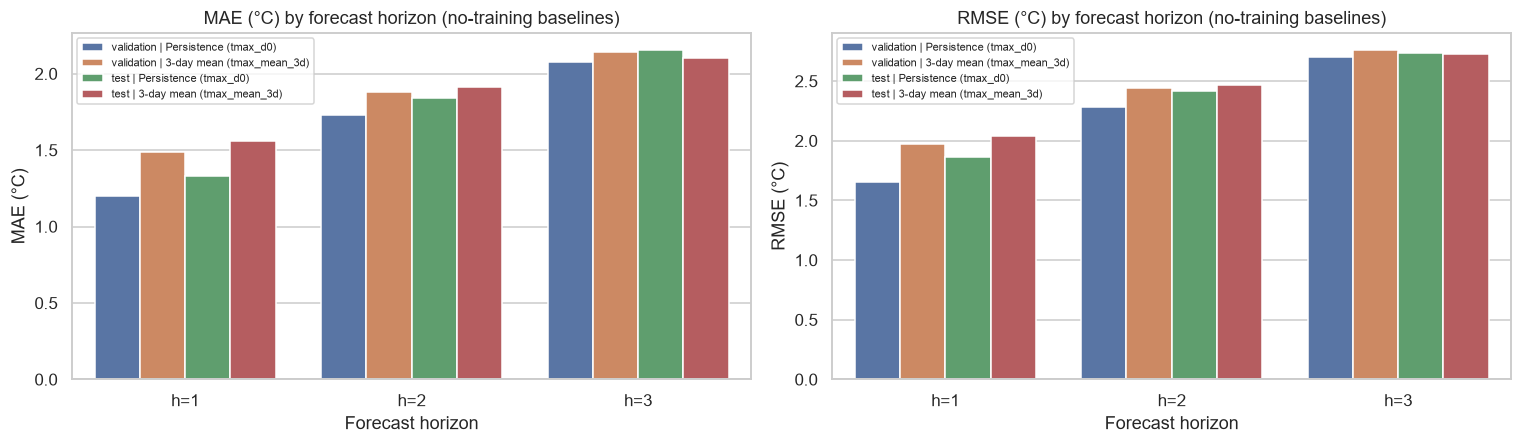

In [18]:
# MAE / RMSE by horizon
pdf = reg_all.reset_index()
pdf = pdf[pdf["horizon"] != "all"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axes, ["MAE (°C)", "RMSE (°C)"]):
    sns.barplot(data=pdf, x="horizon", y=metric, hue=pdf["split"] + " | " + pdf["baseline"], ax=ax)
    ax.set_title(f"{metric} by forecast horizon (no-training baselines)")
    ax.set_xlabel("Forecast horizon"); ax.set_ylabel(metric); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIRS["features"] / "baseline_error_by_horizon.png"); plt.show()

In [19]:
# Classification-style metrics on the heatwave rule (accuracy, precision, recall, F1, support)
clf_rows = []
for s, (Xs, ys) in eval_sets.items():
    for b, fn in baselines.items():
        summ, per_class, cm = classification_metrics(ys, fn(Xs))
        print("=" * 78); print(f"{s.upper()} | {b} | accuracy = {summ['accuracy']:.4f} | support = {summ['total support']}")
        display(per_class.round(3)); display(cm)
        clf_rows.append({"split": s, "baseline": b, **summ})
clf_summary = pd.DataFrame(clf_rows)

support = {s: pd.Series(to_heatwave_codes(ys)).value_counts().reindex(CLASS_LABELS, fill_value=0).to_dict() for s, (_, ys) in eval_sets.items()}
print("\nActual class counts (support) [0 = No, 1 = Heatwave, 2 = Severe]:", support)
print("NOTE: classes 1/2 (>= 45 °C) are very rare here (2025 has none), so accuracy alone is misleading -> read recall + support,")
print("      and treat MAE / RMSE as the main metrics.")
clf_summary.round(4)

VALIDATION | Persistence (tmax_d0) | accuracy = 0.9845 | support = 2193


,precision,recall,f1,support
0 - No Heatwave,0.992,0.992,0.992,2163
1 - Heatwave,0.433,0.433,0.433,30
2 - Severe Heatwave,0.000,0.000,0.000,0


,pred 0,pred 1,pred 2
actual 0,2146,17,0
actual 1,17,13,0
actual 2,0,0,0


VALIDATION | 3-day mean (tmax_mean_3d) | accuracy = 0.9822 | support = 2193


,precision,recall,f1,support
0 - No Heatwave,0.989,0.993,0.991,2163
1 - Heatwave,0.286,0.200,0.235,30
2 - Severe Heatwave,0.000,0.000,0.000,0


,pred 0,pred 1,pred 2
actual 0,2148,15,0
actual 1,24,6,0
actual 2,0,0,0


... (4 outputs left out)

,precision,recall,f1,support
0 - No Heatwave,1.0,1.0,1.0,1095
1 - Heatwave,0.0,0.0,0.0,0
2 - Severe Heatwave,0.0,0.0,0.0,0


,pred 0,pred 1,pred 2
actual 0,1095,0,0
actual 1,0,0,0
actual 2,0,0,0



Actual class counts (support) [0 = No, 1 = Heatwave, 2 = Severe]: {'validation': {0: 2163, 1: 30, 2: 0}, 'test': {0: 1095, 1: 0, 2: 0}}
NOTE: classes 1/2 (>= 45 °C) are very rare here (2025 has none), so accuracy alone is misleading -> read recall + support,
      and treat MAE / RMSE as the main metrics.


,split,baseline,accuracy,macro precision,macro recall,macro F1,weighted F1,total support
0,validation,Persistence (tmax_d0),0.9845,0.7127,0.7127,0.7127,0.9845,2193
1,validation,3-day mean (tmax_mean_3d),0.9822,0.6373,0.5965,0.6131,0.9807,2193
2,test,Persistence (tmax_d0),1.0000,1.0000,1.0000,1.0000,1.0000,1095
3,test,3-day mean (tmax_mean_3d),1.0000,1.0000,1.0000,1.0000,1.0000,1095


EXPORT DATASETS, CONFIGS AND UTILITIES

In [20]:
proc = DIRS["processed"]
out_cols = META_COLS + FEATURE_COLUMNS + [TARGET, "has_missing_predictor"]
sup[out_cols].to_csv(proc / "delhi_supervised_features.csv", index=False)          # un-imputed intermediate
train_p[out_cols].to_csv(proc / "train.csv", index=False)
val_p[out_cols].to_csv(proc / "validation.csv", index=False)
test_p[out_cols].to_csv(proc / "test.csv", index=False)
joblib.dump(imputer, DIRS["models"] / "imputer.joblib")                            # preprocessing artifact (not an ML model)
reg_all.round(4).to_csv(DIRS["reports"] / "baseline_regression_metrics.csv")
clf_summary.round(4).to_csv(DIRS["reports"] / "baseline_classification_metrics.csv", index=False)

feature_defs = {**{f"{v}_d{k}": (f"{v} on day T" if k == 0 else f"{v} on day T-{k}") for v in VARS for k in LAGS},
                "month_sin": "sin(2*pi*(month-1)/12) of TARGET date", "month_cos": "cos(2*pi*(month-1)/12) of TARGET date",
                "day_sin": "sin(2*pi*(day_of_year-1)/days_in_year) of TARGET date (365/366, leap-aware)",
                "day_cos": "cos(2*pi*(day_of_year-1)/days_in_year) of TARGET date (365/366, leap-aware)",
                "tmax_mean_3d": "mean(tmax_d0, tmax_d1, tmax_d2)", "tmax_trend_3d": "tmax_d0 - tmax_d2",
                "humidity_mean_3d": "mean of the 3 humidity values", "solar_sum_3d": "sum of the 3 solar totals",
                "forecast_horizon": "1, 2 or 3 = days ahead of the forecast origin"}

configs = {
    "feature_config.json": {
        "feature_columns_in_order": FEATURE_COLUMNS, "n_features": len(FEATURE_COLUMNS),
        "feature_groups": {"historical_weather": HIST_FEATURES, "seasonal": SEASONAL_FEATURES,
                           "recent_pattern": TREND_FEATURES, "horizon": HORIZON_FEATURE},
        "feature_definitions": feature_defs,
        "target": {"name": TARGET, "definition": "actual Tmax on forecast_origin + forecast_horizon days", "unit": "°C", "type": "continuous"},
        "metadata_columns_not_inputs": META_COLS, "input_window_days": len(LAGS), "forecast_horizons": HORIZONS,
        "units": UNITS, "scaling": "none (tree-based XGBoost does not need it)"},
    "split_config.json": {
        "method": "chronological by TARGET date, no random shuffling",
        "boundaries": {k: {"start": a, "end": b} for k, (a, b) in SPLIT_BOUNDS.items()},
        "row_counts": {n: len(p) for n, p in parts.items()},
        "row_counts_by_horizon": {n: {int(h): int((p["forecast_horizon"] == h).sum()) for h in HORIZONS} for n, p in parts.items()}},
    "preprocessing_config.json": {
        "imputation": {"strategy": "median", "fitted_on": "training split only", "artifact": "models/imputer.joblib",
                       "statistics": dict(zip(FEATURE_COLUMNS, map(float, imputer.statistics_))),
                       "missing_predictor_rows": {n: int(p["has_missing_predictor"].sum()) for n, p in parts.items()},
                       "missing_targets": "rows removed, never filled"},
        "scaling": "none",
        "heatwave_rule": {"type": "simplified absolute temperature (not the full IMD criteria)", "No Heatwave (0)": f"Tmax < {HEATWAVE_C}",
                          "Heatwave (1)": f"{HEATWAVE_C} <= Tmax < {SEVERE_C}", "Severe Heatwave (2)": f"Tmax >= {SEVERE_C}",
                          "used_as_regression_target": False}},
    "dataset_metadata_features.json": {
        "source_file": CLEAN_CSV.name, "source_md5": csv_md5, "rows": len(clean),
        "first_date": str(clean["date"].min().date()), "last_date": str(clean["date"].max().date()),
        "frequency": "daily", "timezone": "Asia/Kolkata", "units": UNITS, "generated_by": "02_model_training.ipynb",
        "note": "Model-derived (ERA5 archive) estimates, not station observations. Archive (training) and operational "
                "Forecast (live) data may come from different model products - validate before live use."},
}
for name, obj in configs.items():
    (DIRS["config"] / name).write_text(json.dumps(obj, indent=2, ensure_ascii=False))

# ---- Reusable src/ modules, generated from the SAME functions used above (no duplicated logic) ----
def export_module(path, header, funcs):
    path.write_text(header + "\n\n" + "\n\n".join(inspect.getsource(f) for f in funcs) + "\n")

feat_header = ('"""Auto-generated from 02_model_training.ipynb - feature engineering for the Delhi Tmax regression."""\n'
               "import numpy as np\nimport pandas as pd\n\n"
               f"VARS = {VARS!r}\nLAGS = {LAGS!r}\nHORIZONS = {HORIZONS!r}\nTARGET = {TARGET!r}\nMETA_COLS = {META_COLS!r}\n"
               f"HIST_FEATURES = {HIST_FEATURES!r}\nSEASONAL_FEATURES = {SEASONAL_FEATURES!r}\n"
               f"TREND_FEATURES = {TREND_FEATURES!r}\nHORIZON_FEATURE = {HORIZON_FEATURE!r}\nFEATURE_COLUMNS = {FEATURE_COLUMNS!r}\n")
rules_header = ('"""Simplified absolute-temperature heatwave rule (NOT the full IMD definition; never a regression target)."""\n'
                f"HEATWAVE_C = {HEATWAVE_C}\nSEVERE_C = {SEVERE_C}\nCATEGORY_NAMES = {CATEGORY_NAMES!r}\n")
eval_header = ('"""Regression + heatwave-category classification metrics."""\n'
               "import numpy as np\nimport pandas as pd\n"
               "from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,\n"
               "                             max_error, accuracy_score, precision_recall_fscore_support, confusion_matrix)\n"
               "from src.heatwave_rules import classify_heatwave, CATEGORY_NAMES\n\nCLASS_LABELS = [0, 1, 2]\n")
try:
    export_module(DIRS["src"] / "features.py", feat_header,
                  [make_calendar, add_historical_features, add_seasonal_features, add_trend_features, build_supervised])
    export_module(DIRS["src"] / "heatwave_rules.py", rules_header, [classify_heatwave])
    export_module(DIRS["src"] / "evaluation.py", eval_header,
                  [regression_metrics, regression_by_horizon, to_heatwave_codes, classification_metrics])
    print("src/ modules written")
except OSError as err:       # source not retrievable in some environments - logic stays in this notebook
    print("Could not export src/ modules:", err)

print("Saved:", [p.name for p in sorted(proc.glob("*.csv"))])
print("Config:", [p.name for p in sorted(DIRS["config"].glob("*.json"))])

src/ modules written
Saved: ['delhi_daily_clean.csv', 'delhi_daily_quality_flags.csv', 'delhi_supervised_features.csv', 'test.csv', 'train.csv', 'validation.csv']
Config: ['dataset_metadata.json', 'dataset_metadata_features.json', 'feature_config.json', 'preprocessing_config.json', 'split_config.json']


PRE-TRAINING READINESS REPORT

In [21]:
per_h = sup["forecast_horizon"].value_counts().sort_index()
readiness_report = f"""# Pre-Training Dataset Summary - Delhi Daily Tmax (3-day forecast)
Generated: {datetime.now():%Y-%m-%d %H:%M}

## Dataset
- Source: {CLEAN_CSV.name} ({len(clean)} days, {clean['date'].min().date()} -> {clean['date'].max().date()}), md5 {csv_md5[:10]}...
- Supervised examples: {len(sup)} | per horizon: {', '.join(f'h={h}: {n}' for h, n in per_h.items())}
- Input features: {X_train.shape[1]} (all numeric) | target: {TARGET} (°C, continuous)

## Chronological split (by target date)
{split_summary.to_string()}

## Target distribution by split and horizon (°C)
{target_stats.reindex(list(parts), level=0).to_string()}

## Missing-value status
{miss.to_string()}
- Imputer: median, fitted on train only (no-op when nothing is missing). Scaling: none.

## No-training baseline metrics (validation + test)
{reg_all.round(3).to_string()}

## Notes
- Data are model-derived (ERA5 archive) estimates, not station observations.
- The heatwave rule (45 / 47 °C) is a simplified project rule, not the full IMD definition.
- Heatwave classes are rare (support: {support}) -> accuracy alone is misleading.
- No XGBoost model was imported, trained, tuned or evaluated.
"""
(DIRS["reports"] / "pretraining_dataset_summary.md").write_text(readiness_report)

fe_report = "# Feature Engineering Report\n\n| # | Feature | Definition |\n|---|---|---|\n" + "\n".join(
    f"| {i} | `{c}` | {feature_defs[c]} |" for i, c in enumerate(FEATURE_COLUMNS, 1))
(DIRS["reports"] / "feature_engineering_report.md").write_text(fe_report)
leak_report = "# Leakage Validation Report\n\n" + "\n".join(f"- {'PASS' if ok else 'FAIL'} - {k}" for k, ok in leak.items())
(DIRS["reports"] / "leakage_validation_report.md").write_text(leak_report)
print(readiness_report)

# Pre-Training Dataset Summary - Delhi Daily Tmax (3-day forecast)
Generated: 2026-11-22 17:13

## Dataset
- Source: delhi_daily_clean.csv (4018 days, 2015-01-01 -> 2025-12-31), md5 a6862fcb32...
- Supervised examples: 12042 | per horizon: h=1: 4015, h=2: 4014, h=3: 4013
- Input features: 21 (all numeric) | target: target_tmax (°C, continuous)

## Chronological split (by target date)
                       target period first target last target first origin last origin  rows  share_%   h=1   h=2   h=3
split                                                                                                                  
train       2015-01-01 -> 2022-12-31   2015-01-04  2022-12-31   2015-01-03  2022-12-30  8754    72.70  2919  2918  2917
validation  2023-01-01 -> 2024-12-31   2023-01-01  2024-12-31   2022-12-29  2024-12-30  2193    18.21   731   731   731
test        2025-01-01 -> 2025-12-31   2025-01-01  2025-12-31   2024-12-29  2025-12-30  1095     9.09   365   365   365

## Target di

In [22]:
final_checks = {
    "exactly 21 candidate input features": len(FEATURE_COLUMNS) == 21 and X_train.shape[1] == 21,
    "target is continuous target_tmax (°C)": pd.api.types.is_float_dtype(y_train),
    "horizons are 1, 2, 3": sorted(sup["forecast_horizon"].unique()) == HORIZONS,
    "train targets 2015-2022 / validation 2023-2024 / test 2025": bool(
        train_df["target_date"].dt.year.between(2015, 2022).all() and val_df["target_date"].dt.year.between(2023, 2024).all()
        and (test_df["target_date"].dt.year == 2025).all()),
    "all leakage checks passed": bool(leak_df["passed"].all()),
    "X/y arrays prepared (train, validation, test)": all(len(a) == len(b) > 0 for a, b in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]),
    "evaluation metrics ready (MSE, MAE, RMSE, R², accuracy, precision, recall, F1, support)": not reg_all.empty and not clf_summary.empty,
    "split / feature / preprocessing configs saved": all((DIRS["config"] / f).exists() for f in ["feature_config.json", "split_config.json", "preprocessing_config.json"]),
    "imputer artifact saved": (DIRS["models"] / "imputer.joblib").exists(),
    "no model imported/trained": "xgboost" not in sys.modules,
}
result = pd.Series(final_checks, name="passed").to_frame()
display(result)
assert result["passed"].all(), "A readiness check failed - review above."
print("\nAll checks passed. STOP POINT reached - next notebook: train the XGBoost regressor on X_train/y_train, tune on X_val/y_val,")
print("evaluate once on X_test/y_test with the functions in src/evaluation.py, then add live Open-Meteo input + Streamlit.")

,passed
exactly 21 candidate input features,True
target is continuous target_tmax (°C),True
"horizons are 1, 2, 3",True
train targets 2015-2022 / validation 2023-2024 / test 2025,True
all leakage checks passed,True
"X/y arrays prepared (train, validation, test)",True
"evaluation metrics ready (MSE, MAE, RMSE, R², accuracy, precision, recall, F1, support)",True
split / feature / preprocessing configs saved,True
imputer artifact saved,True
no model imported/trained,True



All checks passed. STOP POINT reached - next notebook: train the XGBoost regressor on X_train/y_train, tune on X_val/y_val,
evaluate once on X_test/y_test with the functions in src/evaluation.py, then add live Open-Meteo input + Streamlit.
